
# Weather and Electricity Consumption EDA + Feature Engineering
## Atlanta and Birmingham

This notebook performs a complete exploratory analysis of hourly electricity consumption against aligned weather observations for **Atlanta** and **Birmingham**.

### Objectives

1. Assess data quality through missing value, duplicate, and outlier analysis
2. Understand electricity consumption and weather distributions
3. Measure Pearson and Spearman relationships
4. Examine temperature, seasonality, and hourly consumption patterns
5. Identify nonlinear and potentially confounded weather relationships
6. Engineer weather, calendar, seasonal, and lag features
7. Diagnose multicollinearity using VIF
8. Estimate feature importance using a nonlinear tree based model
9. Produce a defensible final feature set for the weather driven electricity consumption model

### Important analytical principle

Raw correlation is **not sufficient** to determine whether a weather variable influences electricity consumption. Temperature, humidity, dew point, season, hour of day, and other variables are strongly related to one another. Therefore, this notebook combines correlation analysis with calendar controls, nonlinear features, VIF diagnostics, and model based feature importance.

> Update the two file paths in the configuration cell before running the notebook.


## 1. Configuration and Imports

In [5]:

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)

# ============================================================
# UPDATE THESE PATHS
# ============================================================
ATLANTA_PATH = Path("atlanta_master.csv")

BIRMINGHAM_PATH = Path("birmingham_master.csv")

# Set these if your columns have different names.
TIMESTAMP_COL = "timestamp"
TARGET_COL = "hourly_load_mw"

# Optional: set to None if your dataset already contains only the
# weather + energy variables needed for this analysis.
CITY_COL = None

sns.set_theme(style="whitegrid")


## 2. Data Loading and Standardization

In [6]:

def load_city_data(path, city_name):
    df = pd.read_csv(path)

    # Standardize column names
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace(r"[^a-z0-9_]", "", regex=True)
    )

    timestamp = TIMESTAMP_COL.lower()
    target = TARGET_COL.lower()

    if timestamp not in df.columns:
        raise KeyError(
            f"{city_name}: timestamp column '{timestamp}' not found. "
            f"Available columns: {list(df.columns)}"
        )

    if target not in df.columns:
        raise KeyError(
            f"{city_name}: target column '{target}' not found. "
            f"Available columns: {list(df.columns)}"
        )

    df[timestamp] = pd.to_datetime(df[timestamp], errors="coerce")
    df = df.sort_values(timestamp).reset_index(drop=True)

    # Remove rows with invalid timestamps
    df = df.dropna(subset=[timestamp]).copy()

    # Remove exact duplicate rows
    df = df.drop_duplicates().reset_index(drop=True)

    df["city"] = city_name

    return df


atlanta = load_city_data(ATLANTA_PATH, "Atlanta")
birmingham = load_city_data(BIRMINGHAM_PATH, "Birmingham")

print("Atlanta:", atlanta.shape)
print("Birmingham:", birmingham.shape)

print("\nAtlanta columns:")
print(atlanta.columns.tolist())

print("\nBirmingham columns:")
print(birmingham.columns.tolist())


Atlanta: (70080, 27)
Birmingham: (70080, 27)

Atlanta columns:
['timestamp', 'hourly_load_mw', 'date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'city']

Birmingham columns:
['timestamp', 'hourly_load_mw', 'date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', '

## 3. Basic Data Audit

In [7]:

def basic_audit(df, city):
    ts = TIMESTAMP_COL.lower()
    target = TARGET_COL.lower()

    print("=" * 70)
    print(city)
    print("=" * 70)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Date range:", df[ts].min(), "to", df[ts].max())
    print("Unique timestamps:", df[ts].nunique())
    print("Duplicate timestamps:", df[ts].duplicated().sum())

    numeric = df.select_dtypes(include=np.number)

    print("\nNumeric summary:")
    display(numeric.describe().T)

    print("\nData types:")
    display(df.dtypes.to_frame("dtype"))


basic_audit(atlanta, "Atlanta")
basic_audit(birmingham, "Birmingham")


Atlanta
Rows: 70080
Columns: 27
Date range: 2016-01-01 00:00:00 to 2023-12-31 23:00:00
Unique timestamps: 70080
Duplicate timestamps: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
hourly_load_mw,70080.0,1.571031e+03,3.267680e+02,9.126581e+02,1.343655e+03,1.492616e+03,1.747899e+03,2.852149e+03
hour,70080.0,1.250000e+01,6.922236e+00,1.000000e+00,6.750000e+00,1.250000e+01,1.825000e+01,2.400000e+01
extraterrestrial_horizontal_radiation_wh_m2,70080.0,3.581695e+02,4.358334e+02,0.000000e+00,0.000000e+00,7.400000e+01,7.450000e+02,1.302000e+03
extraterrestrial_direct_normal_radiation_wh_m2,70080.0,6.835938e+02,6.604898e+02,0.000000e+00,0.000000e+00,6.640000e+02,1.352000e+03,1.415000e+03
global_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direct_normal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diffuse_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sky_cover_tenths,70080.0,5.226741e+00,4.216519e+00,0.000000e+00,0.000000e+00,6.000000e+00,1.000000e+01,1.000000e+01
opaque_sky_cover_tenths,70080.0,4.369963e+00,4.130571e+00,0.000000e+00,0.000000e+00,3.000000e+00,9.000000e+00,1.000000e+01
temperature_c,70080.0,1.677385e+01,9.046354e+00,-2.220000e+01,1.000000e+01,1.780000e+01,2.330000e+01,3.890000e+01



Data types:


,dtype
timestamp,datetime64[us]
hourly_load_mw,float64
date,str
hour,int64
extraterrestrial_horizontal_radiation_wh_m2,float64
extraterrestrial_direct_normal_radiation_wh_m2,float64
global_horizontal_radiation_wh_m2,float64
direct_normal_radiation_wh_m2,float64
diffuse_horizontal_radiation_wh_m2,float64
total_sky_cover_tenths,float64


Birmingham
Rows: 70080
Columns: 27
Date range: 2016-01-01 00:00:00 to 2023-12-31 23:00:00
Unique timestamps: 70080
Duplicate timestamps: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
hourly_load_mw,70080.0,1.321884e+03,2.750649e+02,8.053045e+02,1.129492e+03,1.256038e+03,1.470021e+03,2.324152e+03
hour,70080.0,1.250000e+01,6.922236e+00,1.000000e+00,6.750000e+00,1.250000e+01,1.825000e+01,2.400000e+01
extraterrestrial_horizontal_radiation_wh_m2,70080.0,3.582462e+02,4.362665e+02,0.000000e+00,0.000000e+00,8.300000e+01,7.372500e+02,1.300000e+03
extraterrestrial_direct_normal_radiation_wh_m2,70080.0,6.835040e+02,6.629698e+02,0.000000e+00,0.000000e+00,7.390000e+02,1.352000e+03,1.415000e+03
global_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direct_normal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diffuse_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sky_cover_tenths,70080.0,5.332178e+00,4.089267e+00,0.000000e+00,0.000000e+00,6.000000e+00,1.000000e+01,1.000000e+01
opaque_sky_cover_tenths,70080.0,4.702654e+00,4.033684e+00,0.000000e+00,0.000000e+00,4.000000e+00,9.000000e+00,1.000000e+01
temperature_c,70080.0,1.670626e+01,9.399537e+00,-2.110000e+01,1.000000e+01,1.780000e+01,2.330000e+01,3.890000e+01



Data types:


,dtype
timestamp,datetime64[us]
hourly_load_mw,float64
date,str
hour,int64
extraterrestrial_horizontal_radiation_wh_m2,float64
extraterrestrial_direct_normal_radiation_wh_m2,float64
global_horizontal_radiation_wh_m2,float64
direct_normal_radiation_wh_m2,float64
diffuse_horizontal_radiation_wh_m2,float64
total_sky_cover_tenths,float64


## 4. Missing Value Report

In [8]:

def missing_report(df, city):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100),
        "dtype": df.dtypes.astype(str)
    })
    report = report.sort_values("missing_percent", ascending=False)

    print(f"{city} missing value report")
    display(report)

missing_report(atlanta, "Atlanta")
missing_report(birmingham, "Birmingham")


Atlanta missing value report


,missing_count,missing_percent,dtype
diffuse_horizontal_radiation_wh_m2,70080,100.0,float64
direct_normal_radiation_wh_m2,70080,100.0,float64
global_horizontal_radiation_wh_m2,70080,100.0,float64
date,0,0.0,str
hourly_load_mw,0,0.0,float64
timestamp,0,0.0,datetime64[us]
hour,0,0.0,int64
extraterrestrial_direct_normal_radiation_wh_m2,0,0.0,float64
extraterrestrial_horizontal_radiation_wh_m2,0,0.0,float64
total_sky_cover_tenths,0,0.0,float64


Birmingham missing value report


,missing_count,missing_percent,dtype
diffuse_horizontal_radiation_wh_m2,70080,100.0,float64
direct_normal_radiation_wh_m2,70080,100.0,float64
global_horizontal_radiation_wh_m2,70080,100.0,float64
date,0,0.0,str
hourly_load_mw,0,0.0,float64
timestamp,0,0.0,datetime64[us]
hour,0,0.0,int64
extraterrestrial_direct_normal_radiation_wh_m2,0,0.0,float64
extraterrestrial_horizontal_radiation_wh_m2,0,0.0,float64
total_sky_cover_tenths,0,0.0,float64


## 5. Duplicate Report

In [9]:

def duplicate_report(df, city):
    ts = TIMESTAMP_COL.lower()

    print(f"{city}")
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Duplicate timestamps:", df[ts].duplicated().sum())

    duplicated_timestamps = (
        df.loc[df[ts].duplicated(keep=False), ts]
        .sort_values()
    )

    if len(duplicated_timestamps):
        display(duplicated_timestamps.to_frame(name=ts).head(50))
    else:
        print("No duplicate timestamps found.")

duplicate_report(atlanta, "Atlanta")
duplicate_report(birmingham, "Birmingham")


Atlanta
Exact duplicate rows: 0
Duplicate timestamps: 0
No duplicate timestamps found.
Birmingham
Exact duplicate rows: 0
Duplicate timestamps: 0
No duplicate timestamps found.


## 6. Outlier Detection

In [10]:

def iqr_outlier_report(df, city):
    numeric_cols = df.select_dtypes(include=np.number).columns

    rows = []

    for col in numeric_cols:
        s = df[col].dropna()

        if len(s) == 0:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = ((s < lower) | (s > upper)).sum()

        rows.append({
            "variable": col,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": count,
            "outlier_percent": count / len(s) * 100
        })

    report = pd.DataFrame(rows).sort_values(
        "outlier_percent", ascending=False
    )

    print(f"{city} IQR outlier report")
    display(report)

iqr_outlier_report(atlanta, "Atlanta")
iqr_outlier_report(birmingham, "Birmingham")


Atlanta IQR outlier report


,variable,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent
15,present_weather,1.000000e+09,1.000000e+09,0.000000,1.000000e+09,1.000000e+09,15555,22.196062
20,hourly_precipitation_cm,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,4353,6.211473
0,hourly_load_mw,1.343655e+03,1.747899e+03,404.243769,7.372897e+02,2.354265e+03,1769,2.524258
9,station_pressure_kpa,9.780000e+01,9.840000e+01,0.600000,9.690000e+01,9.930000e+01,1585,2.261701
11,wind_speed_ms,2.800000e+00,5.700000e+00,2.900000,-1.550000e+00,1.005000e+01,1526,2.177511
17,broadband_aerosol_optical_depth,7.700000e-02,1.880000e-01,0.111000,-8.950000e-02,3.545000e-01,1419,2.024829
12,horizontal_visibility_km,1.130000e+01,2.410000e+01,12.800000,-7.900000e+00,4.330000e+01,440,0.627854
18,snow_depth_cm,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,192,0.273973
6,temperature_c,1.000000e+01,2.330000e+01,13.300000,-9.950000e+00,4.325000e+01,171,0.244007
7,dew_point_c,2.200000e+00,1.830000e+01,16.100000,-2.195000e+01,4.245000e+01,47,0.067066


Birmingham IQR outlier report


,variable,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent
15,present_weather,9.999999e+08,1.000000e+09,80.000000,9.999998e+08,1.000000e+09,14563,20.780537
12,horizontal_visibility_km,9.700000e+00,1.290000e+01,3.200000,4.900000e+00,1.770000e+01,11566,16.503995
20,hourly_precipitation_cm,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,4605,6.571062
17,broadband_aerosol_optical_depth,6.900000e-02,1.822500e-01,0.113250,-1.008750e-01,3.521250e-01,3264,4.657534
9,station_pressure_kpa,9.930000e+01,9.990000e+01,0.600000,9.840000e+01,1.008000e+02,1919,2.738299
11,wind_speed_ms,2.300000e+00,4.400000e+00,2.100000,-8.500000e-01,7.550000e+00,1871,2.669806
0,hourly_load_mw,1.129492e+03,1.470021e+03,340.529482,6.186977e+02,1.980816e+03,1826,2.605594
6,temperature_c,1.000000e+01,2.330000e+01,13.300000,-9.950000e+00,4.325000e+01,192,0.273973
18,snow_depth_cm,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,144,0.205479
7,dew_point_c,3.300000e+00,1.890000e+01,15.600000,-2.010000e+01,4.230000e+01,121,0.172660



### Outlier visualization

IQR based outliers should not automatically be deleted. In weather and electricity data, extreme values can represent genuine heat waves, cold periods, storms, or unusual demand events. The decision to remove an observation should therefore be based on domain validity, not only statistical extremeness.


In [11]:

def boxplots(df, city):
    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=df[col])
        plt.title(f"{city}: {col} distribution and outliers")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

# Run when detailed boxplots are desired.
# boxplots(atlanta, "Atlanta")
# boxplots(birmingham, "Birmingham")


## 7. Energy Distribution

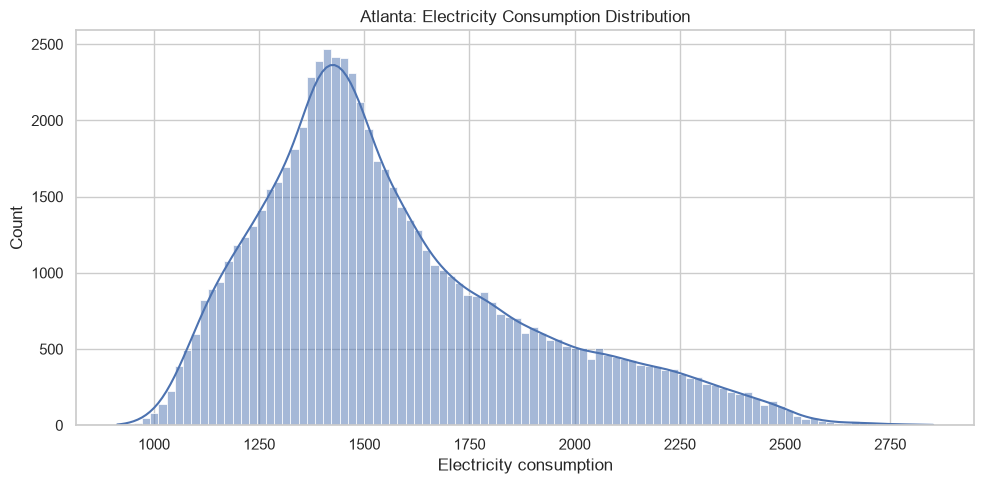

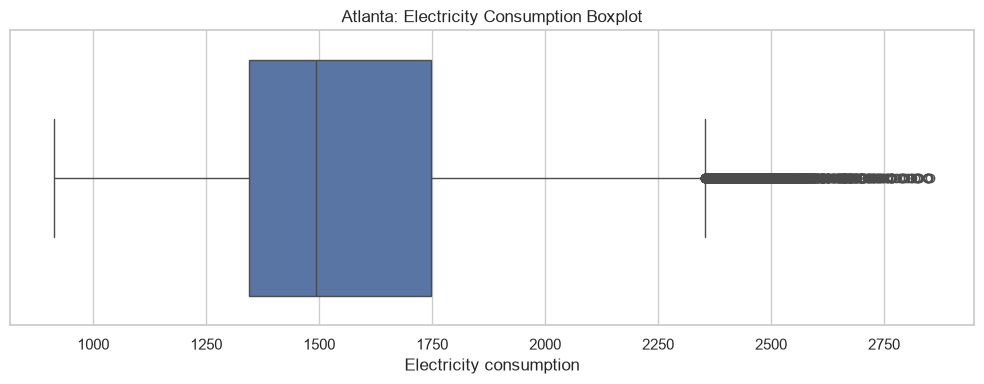

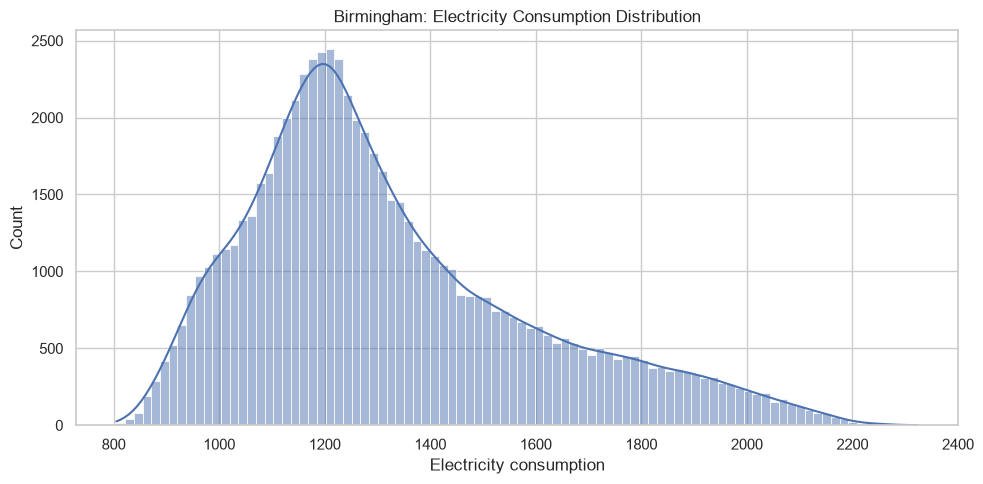

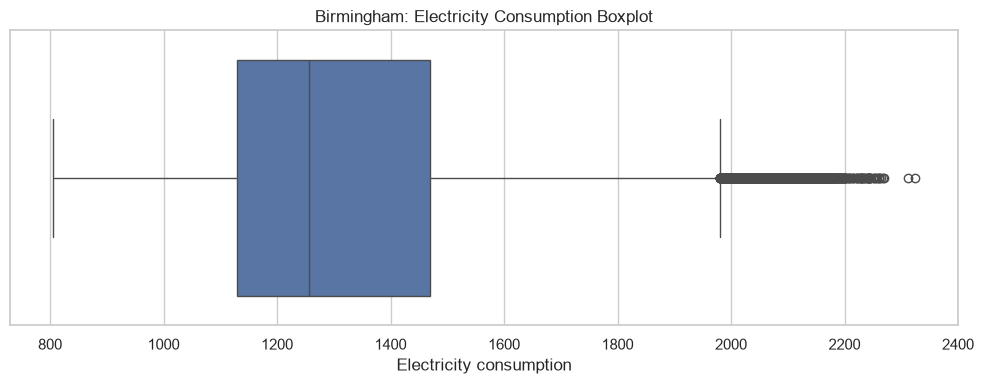

In [12]:

def energy_distribution(df, city):
    target = TARGET_COL.lower()

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(df[target].dropna(), kde=True, ax=ax)
    ax.set_title(f"{city}: Electricity Consumption Distribution")
    ax.set_xlabel("Electricity consumption")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(x=df[target], ax=ax)
    ax.set_title(f"{city}: Electricity Consumption Boxplot")
    ax.set_xlabel("Electricity consumption")
    plt.tight_layout()
    plt.show()

energy_distribution(atlanta, "Atlanta")
energy_distribution(birmingham, "Birmingham")


## 8. Weather Distributions

In [14]:

def weather_distribution(df, city):
    numeric_cols = [
        c for c in df.select_dtypes(include=np.number).columns
        if c != TARGET_COL.lower()
    ]

    for col in numeric_cols:
        fig, ax = plt.subplots(figsize=(9, 4))
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"{city}: {col} Distribution")
        ax.set_xlabel(col)
        plt.tight_layout()
        plt.show()

# Uncomment for all individual distributions.
# weather_distribution(atlanta, "Atlanta")
# weather_distribution(birmingham, "Birmingham")


## 9. Calendar and Seasonal Feature Engineering

In [15]:

def add_calendar_features(df):
    df = df.copy()
    ts = TIMESTAMP_COL.lower()

    df["hour"] = df[ts].dt.hour
    df["day_of_week"] = df[ts].dt.dayofweek
    df["day_name"] = df[ts].dt.day_name()
    df["day_of_month"] = df[ts].dt.day
    df["month"] = df[ts].dt.month
    df["week_of_year"] = df[ts].dt.isocalendar().week.astype(int)
    df["quarter"] = df[ts].dt.quarter
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    # Simple season definition for Northern Hemisphere cities
    season_map = {
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Spring", 4: "Spring", 5: "Spring",
        6: "Summer", 7: "Summer", 8: "Summer",
        9: "Autumn", 10: "Autumn", 11: "Autumn"
    }
    df["season"] = df["month"].map(season_map)

    # Time of day categories
    df["time_period"] = pd.cut(
        df["hour"],
        bins=[-1, 5, 11, 16, 20, 23],
        labels=["Night", "Morning", "Afternoon", "Evening", "Late_Night"]
    )

    return df


atlanta_fe = add_calendar_features(atlanta)
birmingham_fe = add_calendar_features(birmingham)


## 10. Energy by Hour of Day

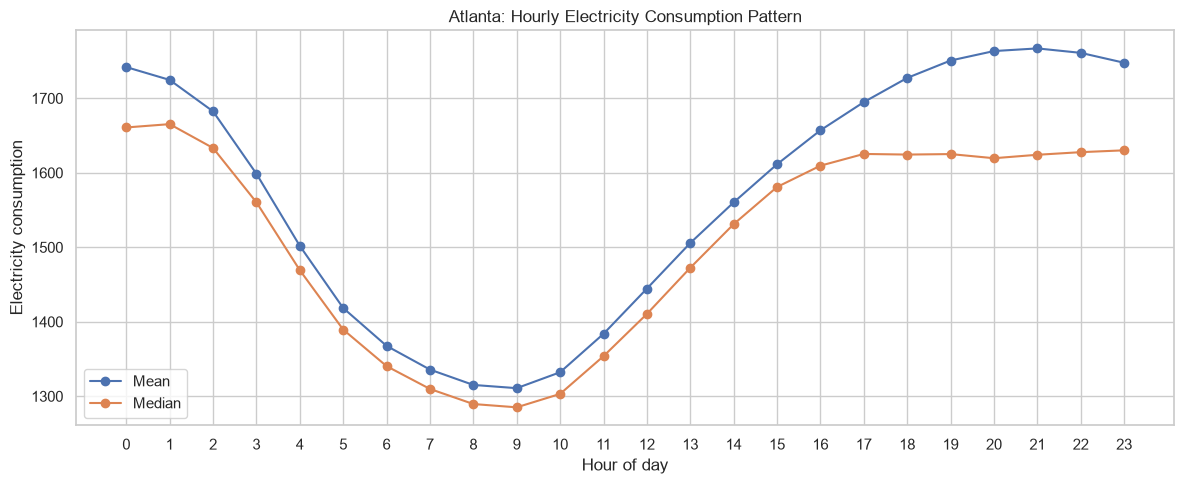

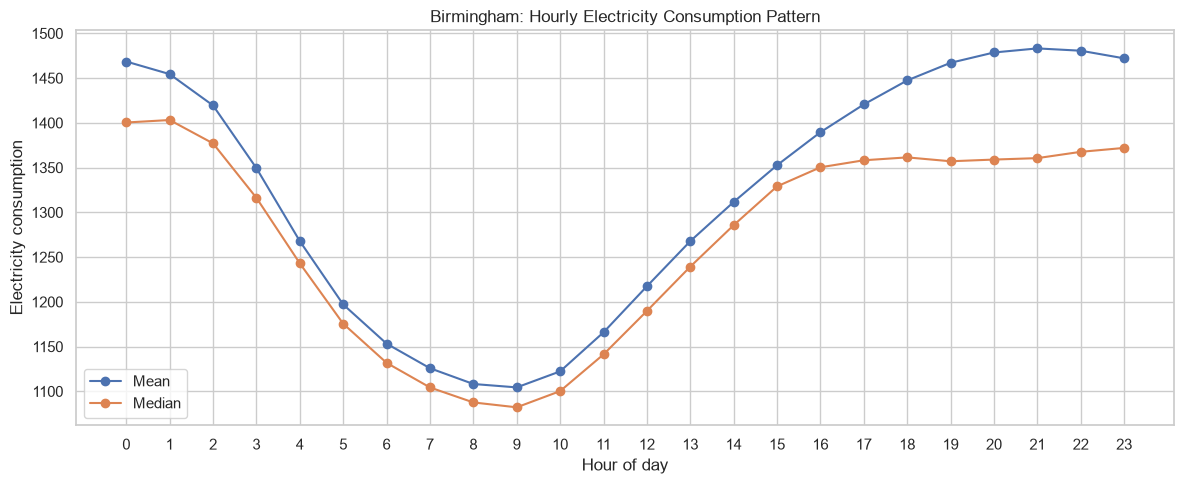

In [16]:

def hourly_energy_plot(df, city):
    target = TARGET_COL.lower()

    hourly = df.groupby("hour")[target].agg(["mean", "median", "std"])

    plt.figure(figsize=(12, 5))
    plt.plot(hourly.index, hourly["mean"], marker="o", label="Mean")
    plt.plot(hourly.index, hourly["median"], marker="o", label="Median")
    plt.xticks(range(24))
    plt.xlabel("Hour of day")
    plt.ylabel("Electricity consumption")
    plt.title(f"{city}: Hourly Electricity Consumption Pattern")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return hourly

atlanta_hourly = hourly_energy_plot(atlanta_fe, "Atlanta")
birmingham_hourly = hourly_energy_plot(birmingham_fe, "Birmingham")


## 11. Energy by Day of Week

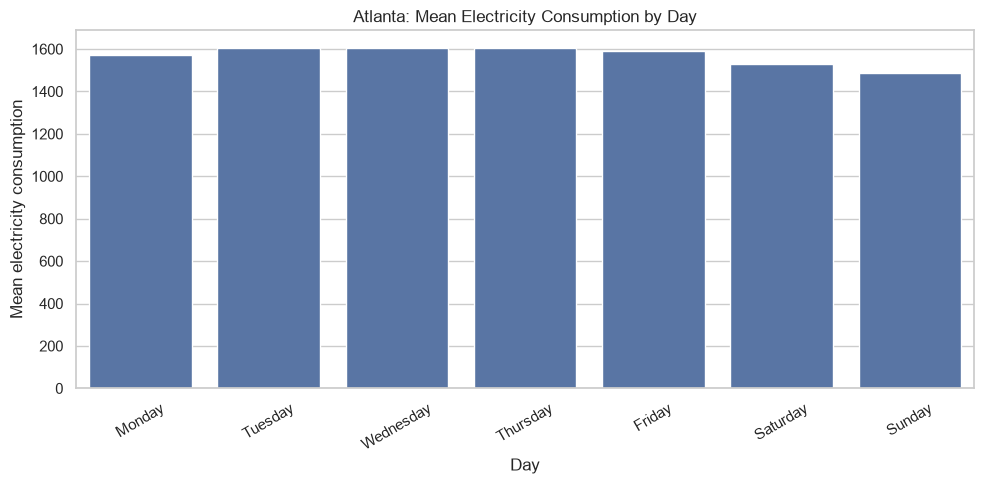

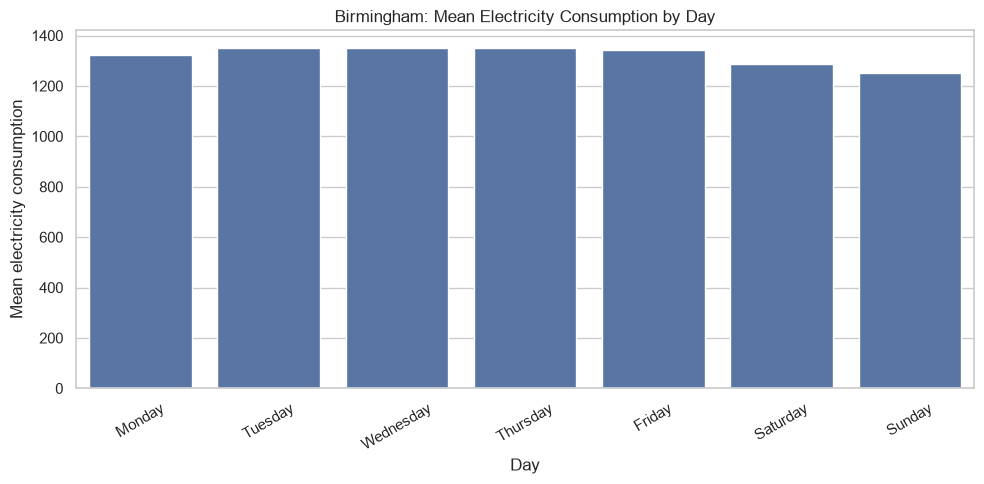

In [17]:

def day_of_week_plot(df, city):
    target = TARGET_COL.lower()

    order = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

    grouped = (
        df.groupby("day_name")[target]
        .mean()
        .reindex(order)
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(x=grouped.index, y=grouped.values)
    plt.title(f"{city}: Mean Electricity Consumption by Day")
    plt.xlabel("Day")
    plt.ylabel("Mean electricity consumption")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

day_of_week_plot(atlanta_fe, "Atlanta")
day_of_week_plot(birmingham_fe, "Birmingham")


## 12. Seasonal Energy Patterns

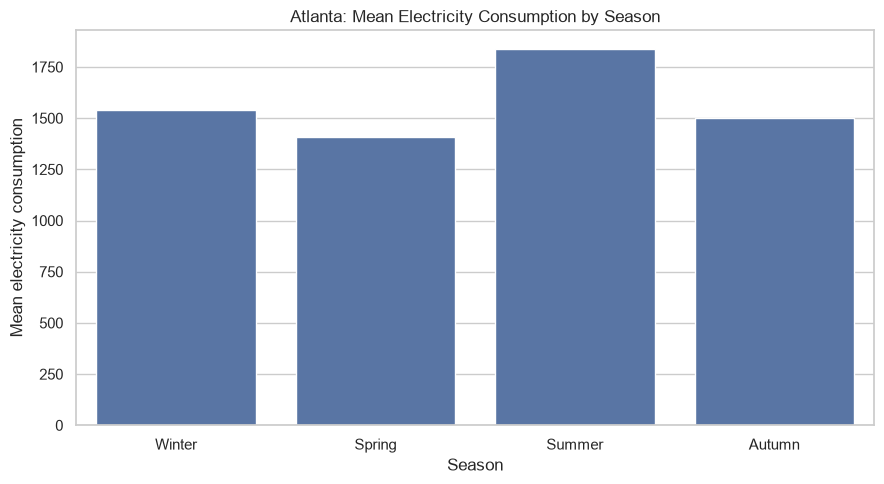

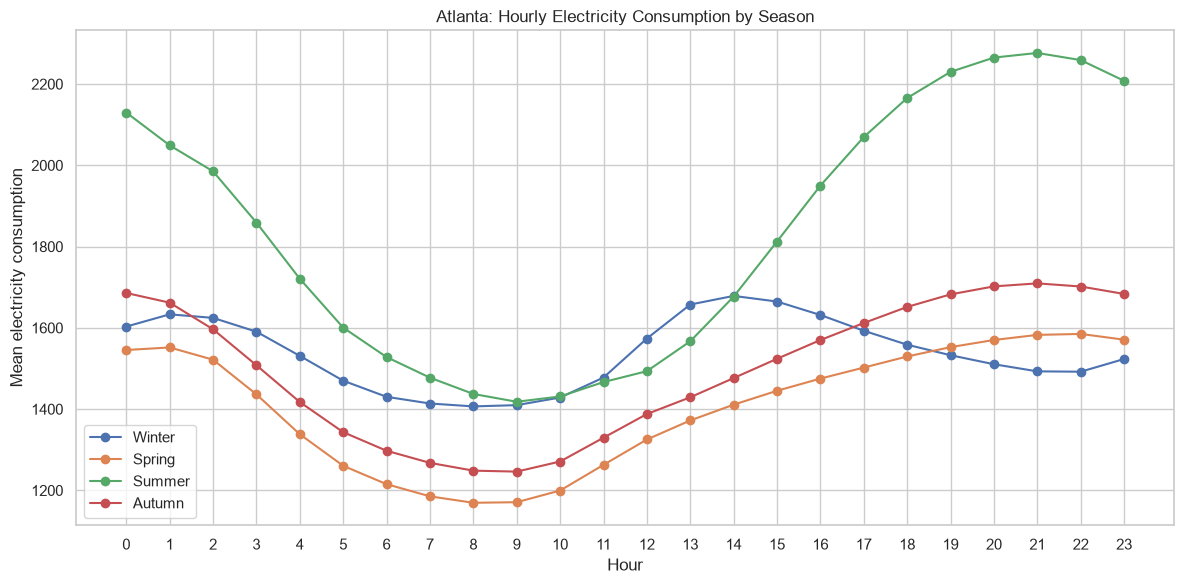

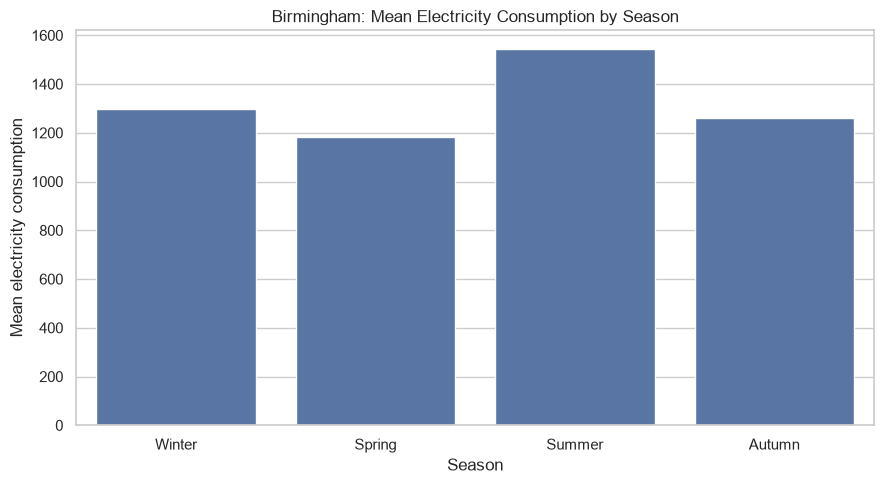

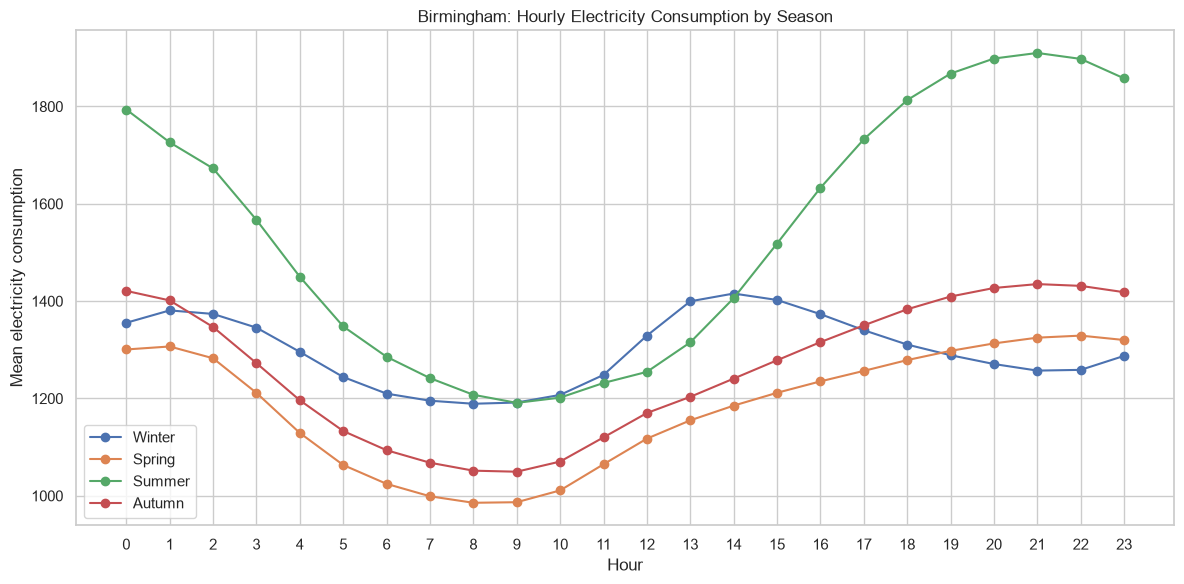

In [18]:

def seasonal_energy_plot(df, city):
    target = TARGET_COL.lower()
    order = ["Winter", "Spring", "Summer", "Autumn"]

    grouped = df.groupby("season")[target].mean().reindex(order)

    plt.figure(figsize=(9, 5))
    sns.barplot(x=grouped.index, y=grouped.values)
    plt.title(f"{city}: Mean Electricity Consumption by Season")
    plt.xlabel("Season")
    plt.ylabel("Mean electricity consumption")
    plt.tight_layout()
    plt.show()

    # Hour by season
    pivot = (
        df.pivot_table(
            index="hour",
            columns="season",
            values=target,
            aggfunc="mean"
        )
        .reindex(columns=order)
    )

    plt.figure(figsize=(12, 6))
    for season in pivot.columns:
        plt.plot(pivot.index, pivot[season], marker="o", label=season)

    plt.xticks(range(24))
    plt.xlabel("Hour")
    plt.ylabel("Mean electricity consumption")
    plt.title(f"{city}: Hourly Electricity Consumption by Season")
    plt.legend()
    plt.tight_layout()
    plt.show()

seasonal_energy_plot(atlanta_fe, "Atlanta")
seasonal_energy_plot(birmingham_fe, "Birmingham")


## 13. Pearson Correlation Matrix

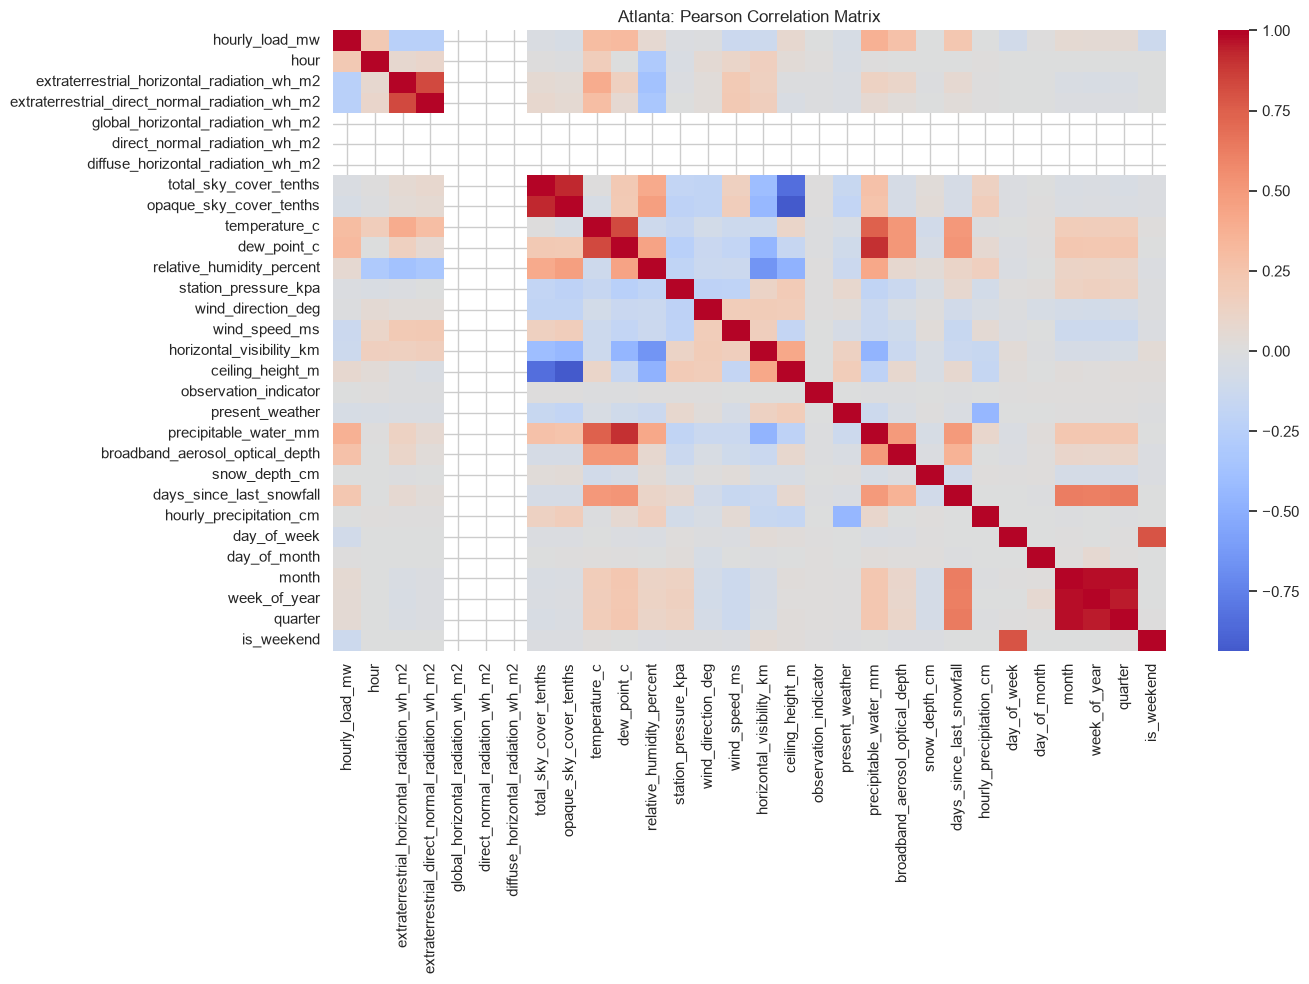

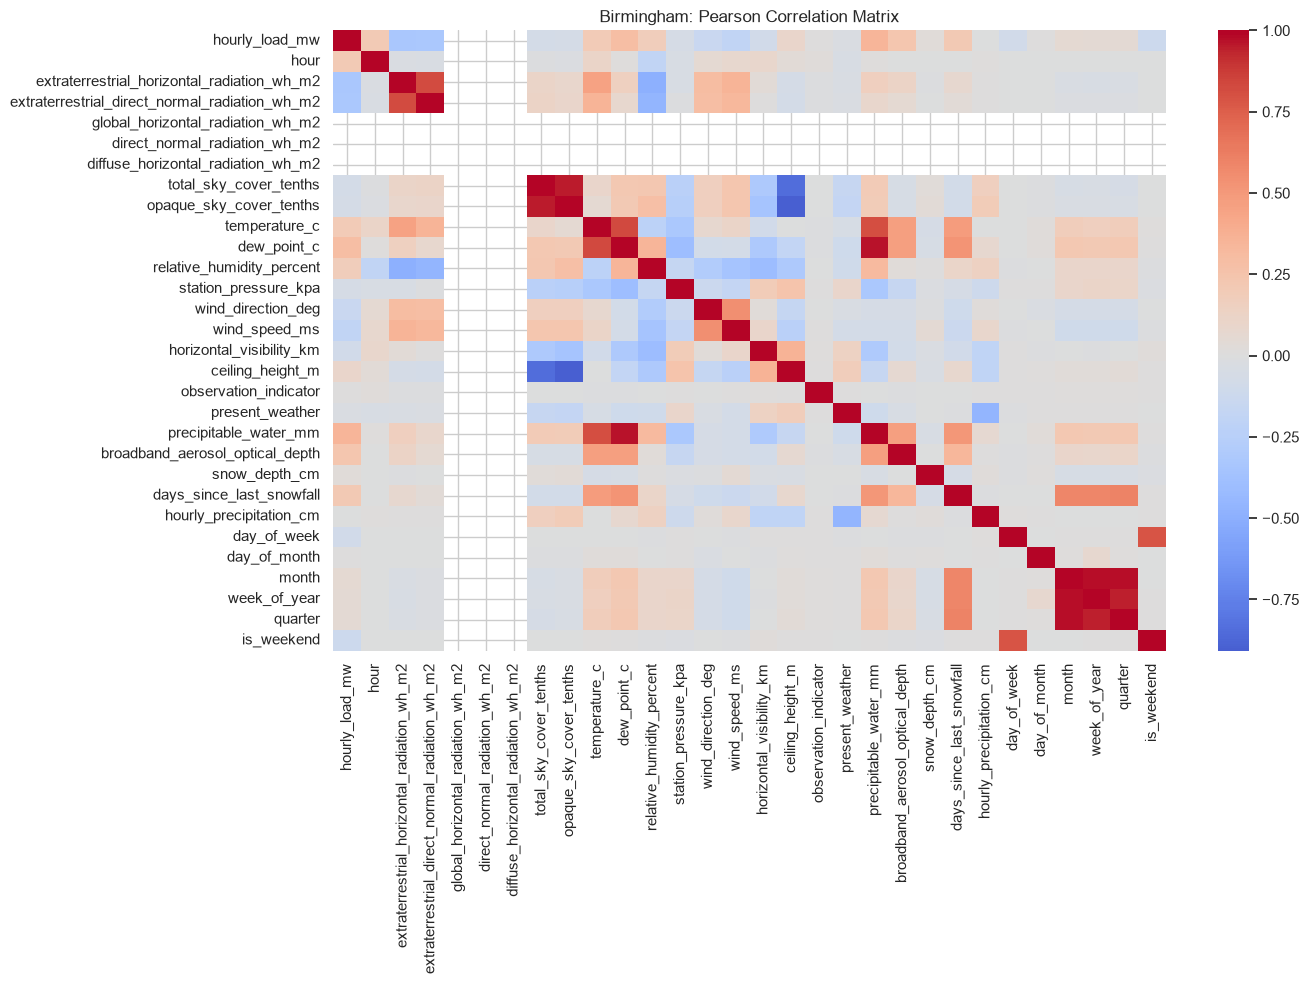

In [19]:

def correlation_matrix(df, city, method="pearson"):
    numeric = df.select_dtypes(include=np.number)

    corr = numeric.corr(method=method)

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        annot=False,
        square=False
    )
    plt.title(f"{city}: {method.title()} Correlation Matrix")
    plt.tight_layout()
    plt.show()

    return corr

atlanta_pearson = correlation_matrix(atlanta_fe, "Atlanta", "pearson")
birmingham_pearson = correlation_matrix(birmingham_fe, "Birmingham", "pearson")


## 14. Spearman Correlation Matrix

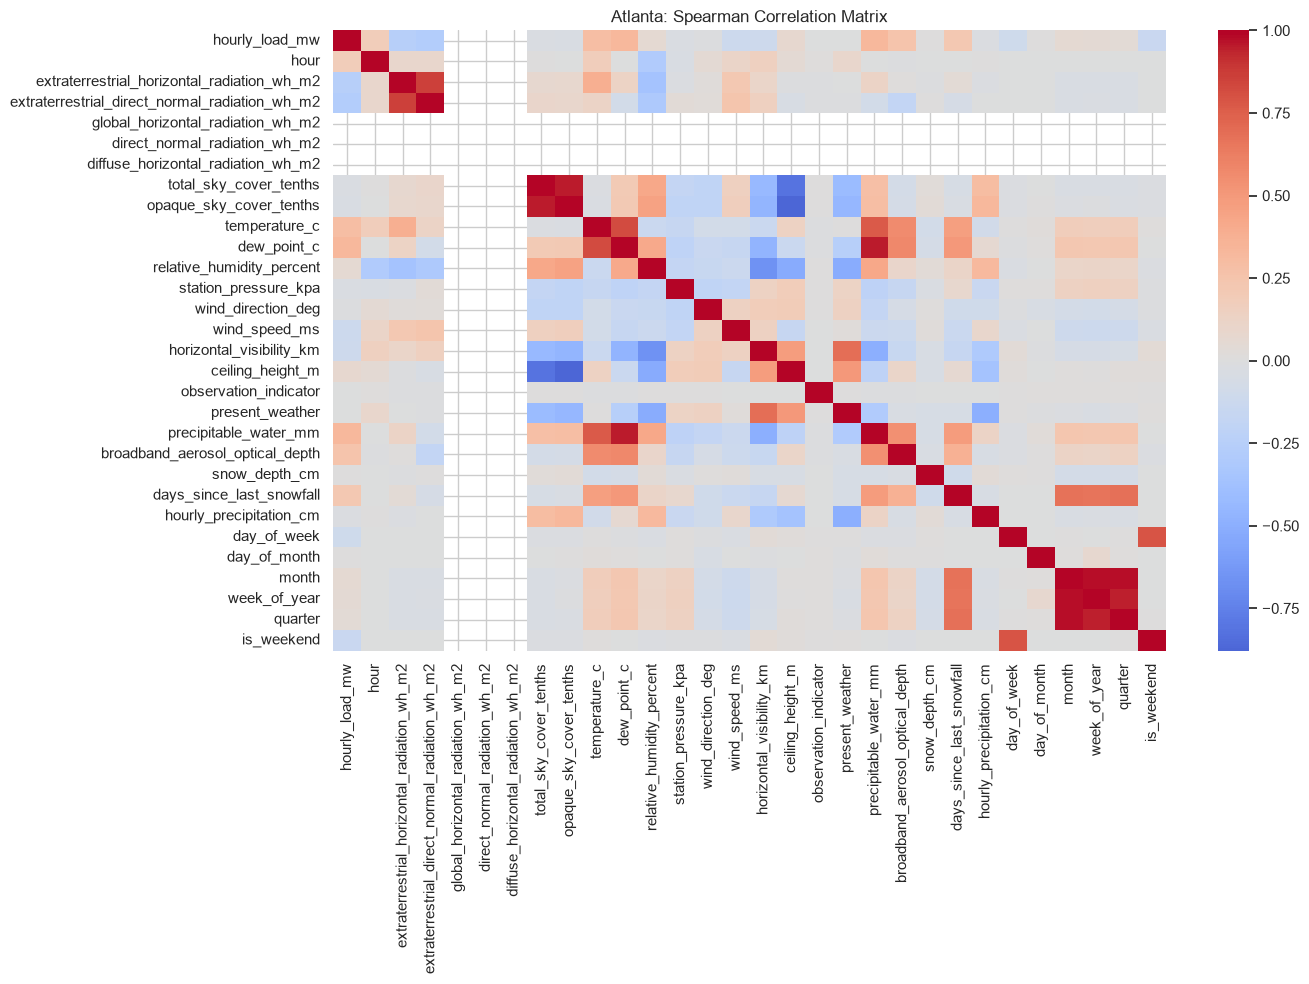

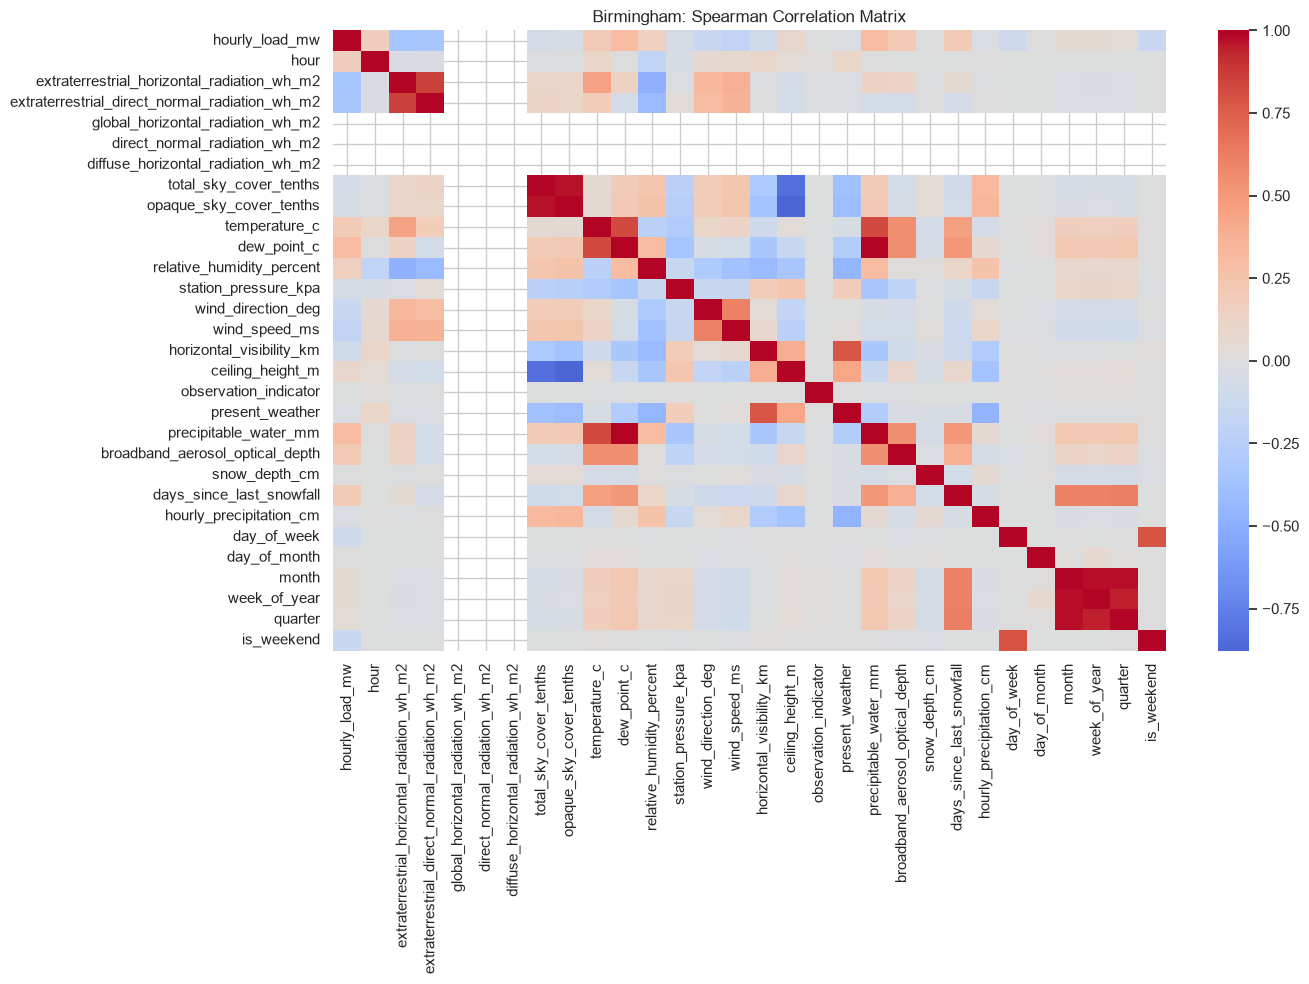

In [20]:

atlanta_spearman = correlation_matrix(atlanta_fe, "Atlanta", "spearman")
birmingham_spearman = correlation_matrix(birmingham_fe, "Birmingham", "spearman")


## 15. Correlation of Weather Variables with Energy

In [21]:

def target_correlations(df, city):
    numeric = df.select_dtypes(include=np.number)
    target = TARGET_COL.lower()

    pearson = numeric.corr(method="pearson")[target].sort_values(
        key=lambda x: x.abs(), ascending=False
    )

    spearman = numeric.corr(method="spearman")[target].sort_values(
        key=lambda x: x.abs(), ascending=False
    )

    report = pd.DataFrame({
        "pearson": pearson,
        "spearman": spearman
    })

    print(f"{city}: Correlation with electricity consumption")
    display(report)

    return report

atlanta_target_corr = target_correlations(atlanta_fe, "Atlanta")
birmingham_target_corr = target_correlations(birmingham_fe, "Birmingham")


Atlanta: Correlation with electricity consumption


,pearson,spearman
broadband_aerosol_optical_depth,0.268956,0.256543
ceiling_height_m,0.070986,0.075023
day_of_month,0.008095,0.002842
day_of_week,-0.090593,-0.107492
days_since_last_snowfall,0.235350,0.217329
dew_point_c,0.313503,0.326124
diffuse_horizontal_radiation_wh_m2,NaN,NaN
direct_normal_radiation_wh_m2,NaN,NaN
extraterrestrial_direct_normal_radiation_wh_m2,-0.244938,-0.273663
extraterrestrial_horizontal_radiation_wh_m2,-0.246019,-0.252453


Birmingham: Correlation with electricity consumption


,pearson,spearman
broadband_aerosol_optical_depth,0.238116,0.200499
ceiling_height_m,0.093591,0.085982
day_of_month,0.007262,0.003687
day_of_week,-0.090816,-0.107464
days_since_last_snowfall,0.212733,0.195914
dew_point_c,0.295105,0.305517
diffuse_horizontal_radiation_wh_m2,NaN,NaN
direct_normal_radiation_wh_m2,NaN,NaN
extraterrestrial_direct_normal_radiation_wh_m2,-0.321673,-0.341876
extraterrestrial_horizontal_radiation_wh_m2,-0.333580,-0.342670



## 16. Temperature vs Energy

Temperature relationships with electricity consumption are often **nonlinear**. In hot climates, demand may rise as temperature increases because of cooling load. In colder periods, demand can also increase because of heating. This can produce a U shaped or asymmetric relationship rather than a simple straight line.


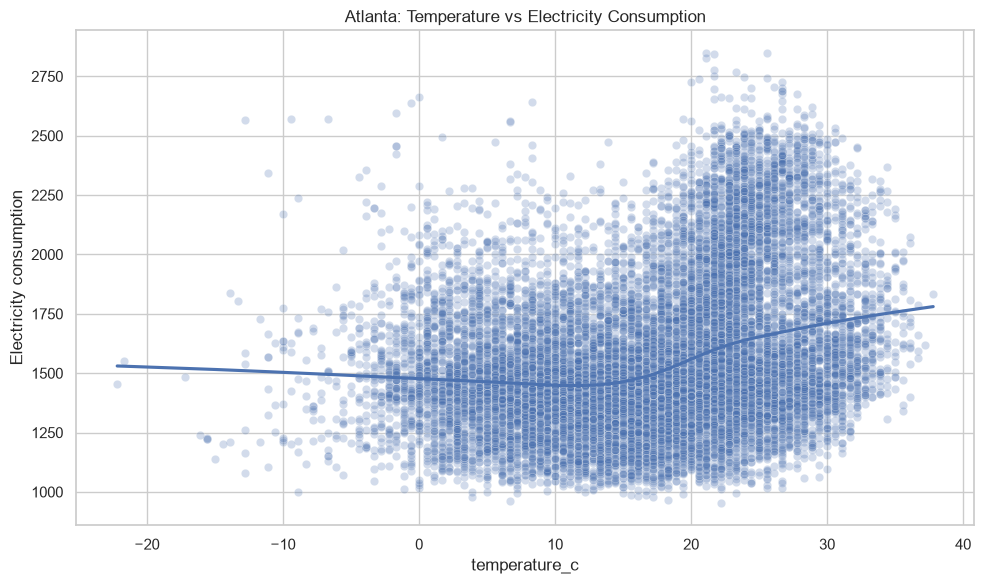

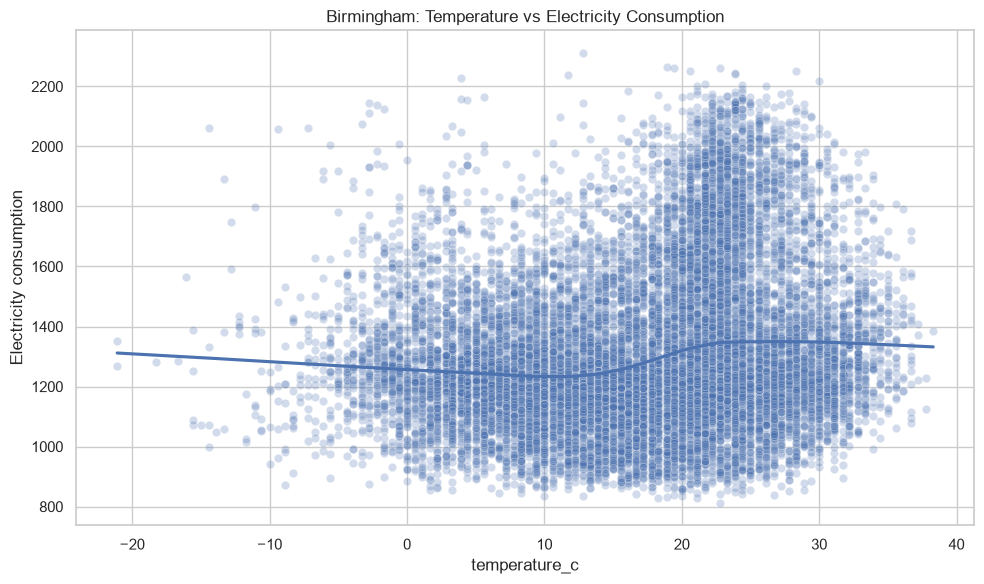

In [22]:

def find_column(df, candidates):
    lower = {c.lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lower:
            return lower[candidate.lower()]

    return None


TEMP_CANDIDATES = [
    "outdoor_temperature",
    "temperature",
    "temp",
    "outdoor_temp",
    "temp_c",
    "temperature_c"
]


def temperature_energy_plot(df, city):
    target = TARGET_COL.lower()
    temp_col = find_column(df, TEMP_CANDIDATES)

    if temp_col is None:
        print(f"{city}: No temperature column found.")
        return

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df.sample(min(15000, len(df)), random_state=42),
        x=temp_col,
        y=target,
        alpha=0.25
    )

    sns.regplot(
        data=df.sample(min(15000, len(df)), random_state=42),
        x=temp_col,
        y=target,
        scatter=False,
        lowess=True
    )

    plt.title(f"{city}: Temperature vs Electricity Consumption")
    plt.xlabel(temp_col)
    plt.ylabel("Electricity consumption")
    plt.tight_layout()
    plt.show()

temperature_energy_plot(atlanta_fe, "Atlanta")
temperature_energy_plot(birmingham_fe, "Birmingham")


## 17. Energy vs Temperature by Season

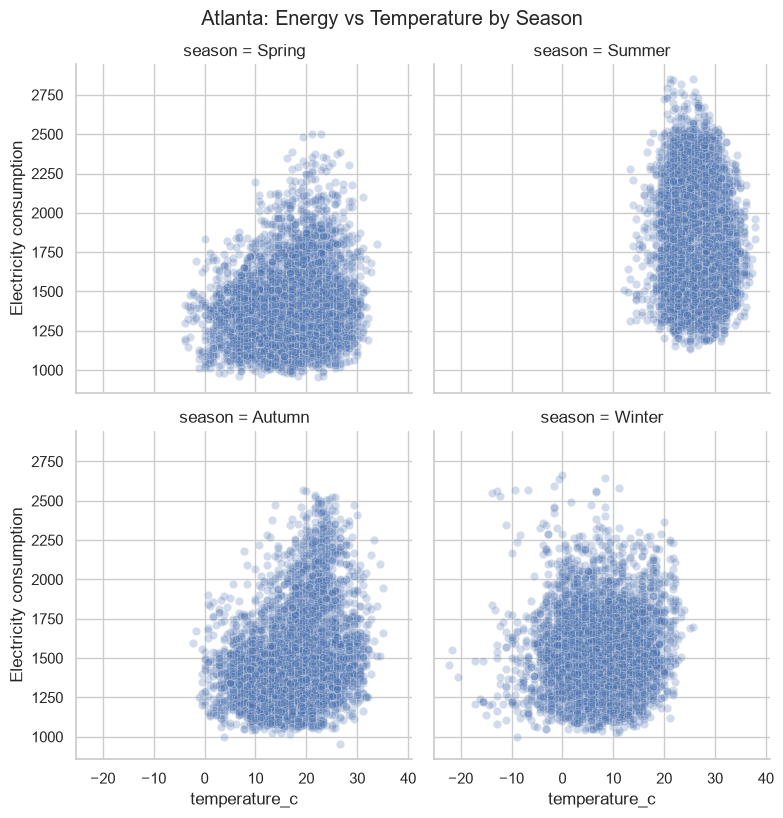

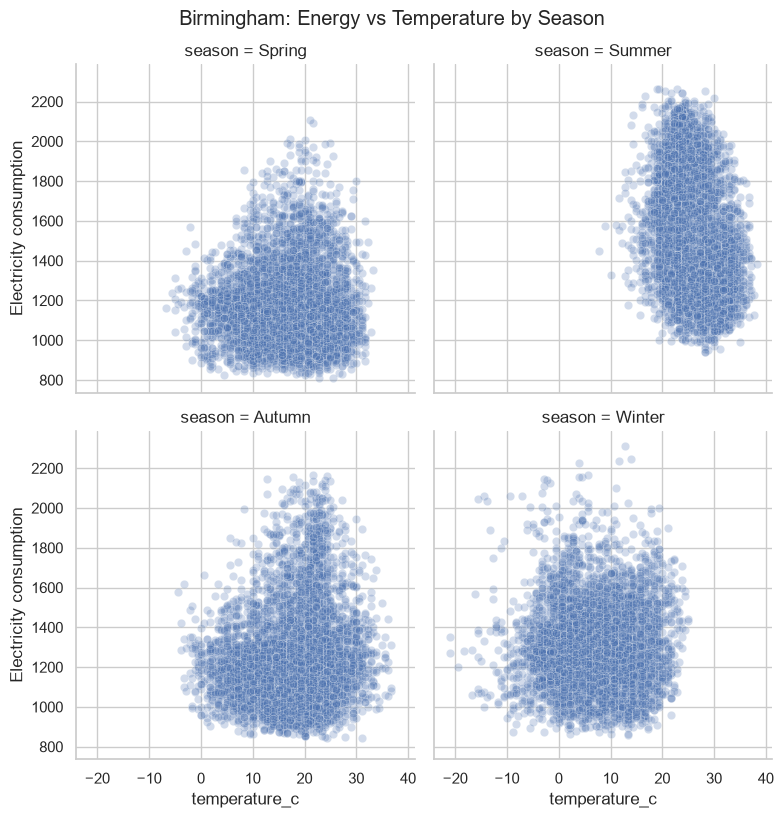

In [23]:

def temperature_by_season(df, city):
    target = TARGET_COL.lower()
    temp_col = find_column(df, TEMP_CANDIDATES)

    if temp_col is None:
        print(f"{city}: No temperature column found.")
        return

    sample = df.sample(min(20000, len(df)), random_state=42)

    g = sns.FacetGrid(
        sample,
        col="season",
        col_wrap=2,
        height=4,
        sharex=True,
        sharey=True
    )

    g.map_dataframe(
        sns.scatterplot,
        x=temp_col,
        y=target,
        alpha=0.25
    )

    g.set_axis_labels(temp_col, "Electricity consumption")
    g.fig.suptitle(f"{city}: Energy vs Temperature by Season", y=1.02)
    plt.show()

temperature_by_season(atlanta_fe, "Atlanta")
temperature_by_season(birmingham_fe, "Birmingham")


## 18. Weather vs Energy Scatterplots

In [24]:

def weather_energy_scatterplots(df, city):
    target = TARGET_COL.lower()

    exclude = {
        target, "hour", "day_of_week", "day_of_month",
        "month", "week_of_year", "quarter", "is_weekend"
    }

    weather_cols = [
        c for c in df.select_dtypes(include=np.number).columns
        if c not in exclude
    ]

    sample = df.sample(min(15000, len(df)), random_state=42)

    for col in weather_cols:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(
            data=sample,
            x=col,
            y=target,
            alpha=0.2
        )
        sns.regplot(
            data=sample,
            x=col,
            y=target,
            scatter=False,
            lowess=True
        )
        plt.title(f"{city}: {col} vs Electricity Consumption")
        plt.tight_layout()
        plt.show()

# Uncomment when you want all scatterplots.
# weather_energy_scatterplots(atlanta_fe, "Atlanta")
# weather_energy_scatterplots(birmingham_fe, "Birmingham")


## 19. Weather Variable Correlation Heatmap

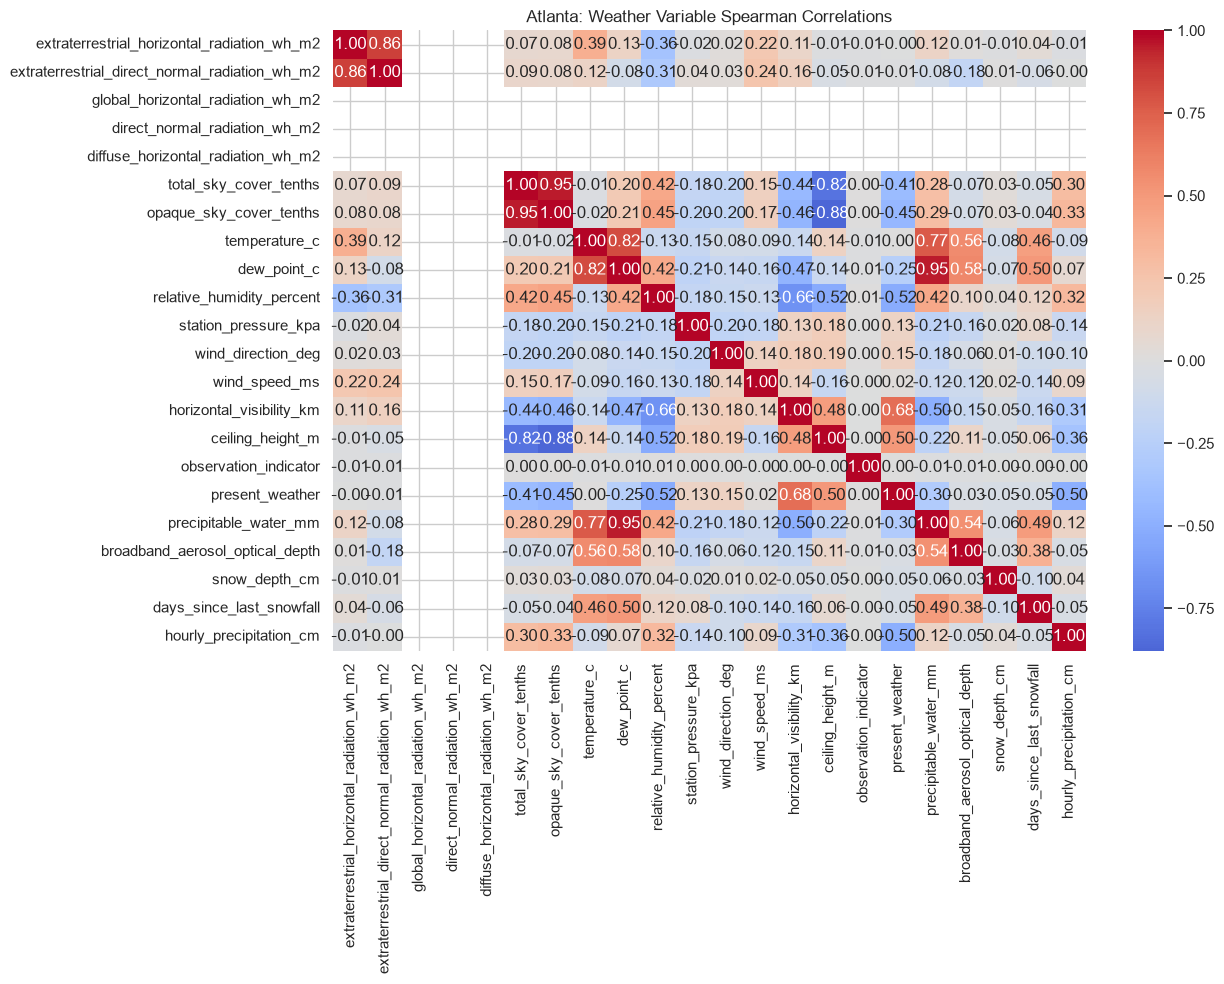

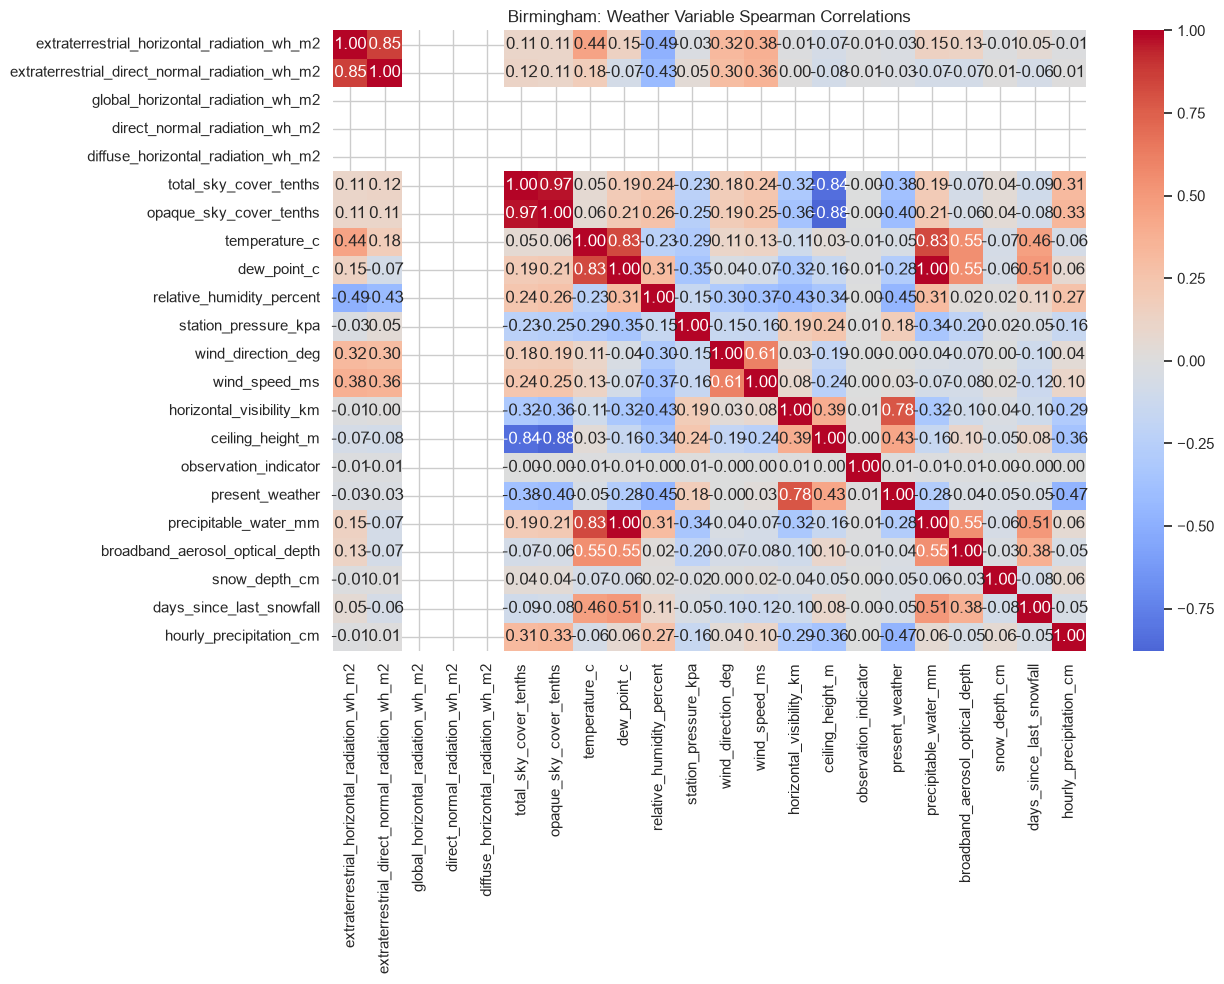

In [25]:

def weather_correlation_heatmap(df, city):
    target = TARGET_COL.lower()

    weather_cols = [
        c for c in df.select_dtypes(include=np.number).columns
        if c not in {
            target, "hour", "day_of_week", "day_of_month",
            "month", "week_of_year", "quarter", "is_weekend"
        }
    ]

    corr = df[weather_cols].corr(method="spearman")

    plt.figure(figsize=(13, 10))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )
    plt.title(f"{city}: Weather Variable Spearman Correlations")
    plt.tight_layout()
    plt.show()

    return corr

atlanta_weather_corr = weather_correlation_heatmap(atlanta_fe, "Atlanta")
birmingham_weather_corr = weather_correlation_heatmap(birmingham_fe, "Birmingham")


## 20. Engineered Weather Features

In [26]:

def add_weather_features(df):
    df = df.copy()

    cols = {c.lower(): c for c in df.columns}

    def first_existing(candidates):
        for c in candidates:
            if c.lower() in cols:
                return cols[c.lower()]
        return None

    temp = first_existing([
        "outdoor_temperature", "temperature", "temp",
        "outdoor_temp", "temp_c", "temperature_c"
    ])

    dew = first_existing([
        "dew_point", "dewpoint", "dew_point_c", "dewpoint_c"
    ])

    rh = first_existing([
        "outdoor_humidity", "humidity", "relative_humidity",
        "rh", "relative_humidity_percent"
    ])

    pressure = first_existing([
        "barometric_pressure", "pressure", "atmospheric_pressure"
    ])

    wind = first_existing([
        "wind_speed", "windspeed"
    ])

    rainfall = first_existing([
        "rainfall", "rain", "precipitation", "precip"
    ])

    solar = first_existing([
        "solar_radiation", "solar", "solar_radiation_w_m2"
    ])

    heat_index = first_existing([
        "heat_index", "heat_index_c"
    ])

    if temp:
        df["temperature_squared"] = df[temp] ** 2
        df["temperature_cubed"] = df[temp] ** 3

        # Cooling and heating degree style features.
        # 18°C and 24°C are treated as analysis thresholds, not
        # claims about the exact operating temperature of the campus.
        df["cooling_degree_proxy_24"] = np.maximum(df[temp] - 24, 0)
        df["heating_degree_proxy_18"] = np.maximum(18 - df[temp], 0)

    if dew and temp:
        df["temperature_dewpoint_spread"] = df[temp] - df[dew]

    if rh and temp:
        df["temp_humidity_interaction"] = df[temp] * df[rh]

    if pressure and temp:
        df["temperature_pressure_interaction"] = df[temp] * df[pressure]

    if wind:
        df["wind_speed_squared"] = df[wind] ** 2

    if rainfall:
        df["rain_indicator"] = (df[rainfall] > 0).astype(int)
        df["rainfall_log1p"] = np.log1p(df[rainfall].clip(lower=0))

    if solar:
        df["solar_squared"] = df[solar] ** 2

    if heat_index and temp:
        df["heat_index_excess"] = df[heat_index] - df[temp]

    return df


atlanta_fe = add_weather_features(atlanta_fe)
birmingham_fe = add_weather_features(birmingham_fe)

print("Atlanta engineered columns:")
print([c for c in atlanta_fe.columns if c not in atlanta.columns])

print("\nBirmingham engineered columns:")
print([c for c in birmingham_fe.columns if c not in birmingham.columns])


Atlanta engineered columns:
['day_of_week', 'day_name', 'day_of_month', 'month', 'week_of_year', 'quarter', 'is_weekend', 'season', 'time_period', 'temperature_squared', 'temperature_cubed', 'cooling_degree_proxy_24', 'heating_degree_proxy_18', 'temperature_dewpoint_spread', 'temp_humidity_interaction']

Birmingham engineered columns:
['day_of_week', 'day_name', 'day_of_month', 'month', 'week_of_year', 'quarter', 'is_weekend', 'season', 'time_period', 'temperature_squared', 'temperature_cubed', 'cooling_degree_proxy_24', 'heating_degree_proxy_18', 'temperature_dewpoint_spread', 'temp_humidity_interaction']


## 21. Lag and Rolling Weather Features

In [27]:

def add_lag_features(df):
    df = df.copy()
    target = TARGET_COL.lower()

    # The project is primarily weather driven, so lags are created
    # for weather variables rather than relying on target lags.
    weather_candidates = [
        c for c in df.select_dtypes(include=np.number).columns
        if c not in {
            target, "hour", "day_of_week", "day_of_month",
            "month", "week_of_year", "quarter", "is_weekend"
        }
    ]

    # Avoid creating hundreds of lag columns.
    preferred_terms = [
        "temperature", "temp", "dew", "humidity", "rh",
        "heat_index", "solar", "wind_speed"
    ]

    selected = [
        c for c in weather_candidates
        if any(term in c.lower() for term in preferred_terms)
    ]

    selected = selected[:12]

    for col in selected:
        df[f"{col}_lag_1"] = df[col].shift(1)
        df[f"{col}_lag_3"] = df[col].shift(3)
        df[f"{col}_lag_24"] = df[col].shift(24)

        df[f"{col}_rolling_mean_3"] = (
            df[col].rolling(3, min_periods=1).mean()
        )
        df[f"{col}_rolling_mean_24"] = (
            df[col].rolling(24, min_periods=1).mean()
        )

    return df


atlanta_fe = add_lag_features(atlanta_fe)
birmingham_fe = add_lag_features(birmingham_fe)



## 22. VIF Multicollinearity Analysis

Variance Inflation Factor measures how strongly each feature can be explained by the other predictors.

A high VIF does **not** mean the variable is unimportant. It means that the variable carries information that overlaps substantially with other variables. This is especially relevant for temperature, dew point, humidity, heat index, and engineered temperature features.

For a regression model, a practical interpretation is:

* VIF below 5: generally acceptable
* VIF from 5 to 10: investigate
* VIF above 10: strong multicollinearity

These are diagnostic thresholds, not absolute rules.


In [38]:
def vif_report(df, city):
    target = TARGET_COL.lower()

    # Start with the ORIGINAL weather variables only.
    # Do not include lag, rolling, squared, cubed or interaction
    # features in the initial VIF analysis.
    
    preferred_weather = [
        "temperature_c",
        "dew_point_c",
        "relative_humidity_percent",
        "station_pressure_kpa",
        "wind_direction_deg",
        "wind_speed_ms",
        "horizontal_visibility_km",
        "ceiling_height_m",
        "precipitable_water_mm",
        "hourly_precipitation_cm",
        "snow_depth_cm",
        "days_since_last_snowfall",
        "total_sky_cover_tenths",
        "opaque_sky_cover_tenths",
        "global_horizontal_radiation_wh_m2",
        "direct_normal_radiation_wh_m2",
        "diffuse_horizontal_radiation_wh_m2"
    ]

    # Keep only columns that actually exist
    weather_cols = [
        col for col in preferred_weather
        if col in df.columns
    ]

    print(f"{city} weather variables used for VIF:")
    print(weather_cols)

    if len(weather_cols) < 2:
        print(f"\nNot enough variables to calculate VIF for {city}.")
        return pd.DataFrame(columns=["feature", "VIF"])

    X = df[weather_cols].copy()

    # Replace infinite values
    X = X.replace([np.inf, -np.inf], np.nan)

    # Convert everything to numeric
    X = X.apply(pd.to_numeric, errors="coerce")

    # Remove rows containing missing values
    X = X.dropna()

    # Remove constant columns
    X = X.loc[:, X.nunique() > 1]

    if X.shape[1] < 2:
        print(f"\nNot enough non-constant variables for VIF in {city}.")
        return pd.DataFrame(columns=["feature", "VIF"])

    # Add constant
    X_with_constant = add_constant(
        X,
        has_constant="add"
    )

    rows = []

    for i, col in enumerate(X_with_constant.columns):

        if col == "const":
            continue

        try:
            vif_value = variance_inflation_factor(
                X_with_constant.values,
                i
            )

            if np.isfinite(vif_value):
                rows.append({
                    "feature": col,
                    "VIF": vif_value
                })
            else:
                rows.append({
                    "feature": col,
                    "VIF": np.inf
                })

        except Exception as e:
            print(f"Could not calculate VIF for {col}: {e}")

    # IMPORTANT: handle empty result safely
    if not rows:
        print(f"\nNo VIF values could be calculated for {city}.")
        return pd.DataFrame(columns=["feature", "VIF"])

    report = (
        pd.DataFrame(rows)
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

    print(f"\n{city}: VIF Report")
    display(report)

    return report


# Calculate VIF
atlanta_vif = vif_report(
    atlanta_fe,
    "Atlanta"
)

birmingham_vif = vif_report(
    birmingham_fe,
    "Birmingham"
)

Atlanta weather variables used for VIF:
['temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'precipitable_water_mm', 'hourly_precipitation_cm', 'snow_depth_cm', 'days_since_last_snowfall', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2']

Not enough non-constant variables for VIF in Atlanta.
Birmingham weather variables used for VIF:
['temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'precipitable_water_mm', 'hourly_precipitation_cm', 'snow_depth_cm', 'days_since_last_snowfall', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2']


## 23. Feature Importance

## 24. Controlled Weather Analysis

## 25. Final Recommended Feature List

In [35]:

# Recommended feature groups for the next predictive model.
#
# Keep the exact names that exist in your dataset. This cell creates
# a candidate list automatically so it can be reviewed before model
# training.

def recommended_features(df):
    target = TARGET_COL.lower()

    candidates = []

    # Core weather dimensions
    weather_priority_terms = [
        "temperature",
        "temp",
        "dew",
        "humidity",
        "rh",
        "pressure",
        "wind",
        "rain",
        "precip",
        "solar",
        "uv",
        "heat_index"
    ]

    for col in df.columns:
        if col == target:
            continue

        if any(term in col.lower() for term in weather_priority_terms):
            candidates.append(col)

    # Calendar controls
    for col in [
        "hour",
        "day_of_week",
        "is_weekend",
        "month",
        "quarter"
    ]:
        if col in df.columns:
            candidates.append(col)

    # Engineered nonlinear weather terms
    for col in df.columns:
        if any(
            term in col.lower()
            for term in [
                "squared",
                "cubed",
                "degree_proxy",
                "spread",
                "interaction",
                "excess"
            ]
        ):
            candidates.append(col)

    # Lag / rolling weather terms
    for col in df.columns:
        if "lag_" in col.lower() or "rolling_" in col.lower():
            candidates.append(col)

    return list(dict.fromkeys(candidates))


atlanta_recommended = recommended_features(atlanta_fe)
birmingham_recommended = recommended_features(birmingham_fe)

print("Atlanta recommended candidate features:")
print(atlanta_recommended)

print("\nBirmingham recommended candidate features:")
print(birmingham_recommended)


Atlanta recommended candidate features:
['temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'precipitable_water_mm', 'hourly_precipitation_cm', 'temperature_squared', 'temperature_cubed', 'temperature_dewpoint_spread', 'temp_humidity_interaction', 'temperature_c_lag_1', 'temperature_c_lag_3', 'temperature_c_lag_24', 'temperature_c_rolling_mean_3', 'temperature_c_rolling_mean_24', 'dew_point_c_lag_1', 'dew_point_c_lag_3', 'dew_point_c_lag_24', 'dew_point_c_rolling_mean_3', 'dew_point_c_rolling_mean_24', 'relative_humidity_percent_lag_1', 'relative_humidity_percent_lag_3', 'relative_humidity_percent_lag_24', 'relative_humidity_percent_rolling_mean_3', 'relative_humidity_percent_rolling_mean_24', 'wind_speed_ms_lag_1', 'wind_speed_ms_lag_3', 'wind_speed_ms_lag_24', 'wind_speed_ms_rolling_mean_3', 'wind_speed_ms_rolling_mean_24', 'temperature_squared_lag_1', 'temperature_squared_lag_3', 'temperature_squared_lag_24', '


## 26. Final Interpretation Framework

Do **not** conclude that a weather variable influences electricity consumption simply because it has the largest Pearson correlation.

The final interpretation should compare four pieces of evidence:

1. **Pearson correlation**  
   Measures linear association.

2. **Spearman correlation**  
   Detects monotonic association even when the relationship is not linear.

3. **Controlled nonlinear model importance**  
   Tests whether the variable contributes predictive information after calendar variables are included.

4. **Multicollinearity/VIF**  
   Determines whether a variable is largely redundant with other weather variables.

### Expected interpretation

Temperature, dew point, humidity, and atmospheric moisture are likely to form the main weather dimension affecting electricity consumption. However, temperature can have a nonlinear relationship with demand, while dew point and humidity can overlap strongly with temperature.

Therefore:

* Retain temperature and nonlinear temperature features.
* Evaluate dew point and humidity together rather than interpreting either in isolation.
* Use heat index or temperature humidity interactions where they improve model performance.
* Keep calendar variables such as hour, day of week, weekend, month, and season as controls.
* Treat pressure, wind, rainfall, solar radiation, and UV as secondary candidates whose inclusion should be justified by feature importance and validation performance.
* Do not blindly retain highly collinear variables simply because they correlate with energy.
* Avoid target lag features if the objective is specifically to estimate **expected electricity consumption from weather and operating context**, rather than performing conventional time series forecasting.

### Important distinction

The analysis establishes **association and predictive contribution**, not causal influence. A defensible statement is:

> "These weather variables provide the strongest statistical and predictive information about electricity consumption after accounting for temporal patterns."

That is substantially stronger than simply saying:

> "Temperature has a correlation of X with electricity consumption."


## 27. Export Cleaned Feature Engineering Data

In [36]:

# Save the engineered datasets for the next modeling stage.

atlanta_fe.to_csv("atlanta_eda_feature_engineered.csv", index=False)
birmingham_fe.to_csv("birmingham_eda_feature_engineered.csv", index=False)

print("Saved:")
print("  atlanta_eda_feature_engineered.csv")
print("  birmingham_eda_feature_engineered.csv")


Saved:
  atlanta_eda_feature_engineered.csv
  birmingham_eda_feature_engineered.csv



# End of EDA

At the end of this notebook you should have:

* Data quality reports
* Outlier diagnostics
* Energy and weather distributions
* Pearson and Spearman correlation matrices
* Temperature and seasonal analysis
* Hourly and weekly consumption patterns
* Weather versus energy relationships
* Weather multicollinearity diagnostics
* Engineered weather features
* Weather lag and rolling features
* Random Forest and permutation feature importance
* A controlled weather feature importance analysis
* Candidate final feature sets for Atlanta and Birmingham

The next modeling notebook can use the exported engineered datasets and compare models such as Multiple Linear Regression, Polynomial Regression, Random Forest, XGBoost, and the LSTM architecture already being developed for the project.


In [37]:
from pathlib import Path
import pandas as pd
import numpy as np

report_file = Path("EDA_Atlanta_Birmingham_Report.txt")

with open(report_file, "w", encoding="utf-8") as f:

    # ============================================================
    # TITLE
    # ============================================================

    f.write("=" * 80 + "\n")
    f.write("ATLANTA AND BIRMINGHAM\n")
    f.write("WEATHER + ELECTRICITY CONSUMPTION EDA REPORT\n")
    f.write("=" * 80 + "\n\n")

    f.write(
        "Target variable: hourly_load_mw\n"
        "Timestamp variable: timestamp\n\n"
    )

    # ============================================================
    # BASIC DATA INFORMATION
    # ============================================================

    f.write("=" * 80 + "\n")
    f.write("1. BASIC DATA INFORMATION\n")
    f.write("=" * 80 + "\n\n")

    for city, df in [
        ("Atlanta", atlanta),
        ("Birmingham", birmingham)
    ]:

        f.write(f"\n--- {city} ---\n")

        f.write(f"Rows: {len(df)}\n")
        f.write(f"Columns: {len(df.columns)}\n")

        f.write(
            f"Date range: "
            f"{df['timestamp'].min()} "
            f"to "
            f"{df['timestamp'].max()}\n"
        )

        f.write(
            f"Unique timestamps: "
            f"{df['timestamp'].nunique()}\n"
        )

        f.write(
            f"Duplicate timestamps: "
            f"{df['timestamp'].duplicated().sum()}\n"
        )

        f.write("\nColumns:\n")

        for col in df.columns:
            f.write(f"  {col}\n")

    # ============================================================
    # MISSING VALUES
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("2. MISSING VALUE REPORT\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta),
        ("Birmingham", birmingham)
    ]:

        f.write(f"\n--- {city} ---\n")

        missing = pd.DataFrame({
            "missing_count": df.isna().sum(),
            "missing_percent": df.isna().mean() * 100
        })

        missing = missing[
            missing["missing_count"] > 0
        ].sort_values(
            "missing_percent",
            ascending=False
        )

        if len(missing) == 0:
            f.write("No missing values.\n")
        else:
            f.write(
                missing.to_string()
            )
            f.write("\n")

    # ============================================================
    # DUPLICATES
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("3. DUPLICATE REPORT\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta),
        ("Birmingham", birmingham)
    ]:

        f.write(f"\n--- {city} ---\n")

        f.write(
            f"Exact duplicate rows: "
            f"{df.duplicated().sum()}\n"
        )

        f.write(
            f"Duplicate timestamps: "
            f"{df['timestamp'].duplicated().sum()}\n"
        )

    # ============================================================
    # OUTLIERS
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("4. OUTLIER REPORT (IQR METHOD)\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta),
        ("Birmingham", birmingham)
    ]:

        f.write(f"\n--- {city} ---\n")

        numeric_cols = df.select_dtypes(
            include=np.number
        ).columns

        rows = []

        for col in numeric_cols:

            s = df[col].dropna()

            if len(s) == 0:
                continue

            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)

            iqr = q3 - q1

            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr

            count = (
                (s < lower) |
                (s > upper)
            ).sum()

            rows.append({
                "variable": col,
                "outlier_count": count,
                "outlier_percent": (
                    count / len(s) * 100
                )
            })

        outliers = (
            pd.DataFrame(rows)
            .sort_values(
                "outlier_percent",
                ascending=False
            )
        )

        f.write(
            outliers.to_string(index=False)
        )

        f.write("\n")

    # ============================================================
    # PEARSON CORRELATION
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("5. PEARSON CORRELATION WITH ELECTRICITY\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta_fe),
        ("Birmingham", birmingham_fe)
    ]:

        f.write(f"\n--- {city} ---\n")

        numeric = df.select_dtypes(
            include=np.number
        )

        corr = (
            numeric
            .corr(method="pearson")["hourly_load_mw"]
            .sort_values(
                key=lambda x: x.abs(),
                ascending=False
            )
        )

        f.write(
            corr.to_string()
        )

        f.write("\n")

    # ============================================================
    # SPEARMAN CORRELATION
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("6. SPEARMAN CORRELATION WITH ELECTRICITY\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta_fe),
        ("Birmingham", birmingham_fe)
    ]:

        f.write(f"\n--- {city} ---\n")

        numeric = df.select_dtypes(
            include=np.number
        )

        corr = (
            numeric
            .corr(method="spearman")["hourly_load_mw"]
            .sort_values(
                key=lambda x: x.abs(),
                ascending=False
            )
        )

        f.write(
            corr.to_string()
        )

        f.write("\n")

    # ============================================================
    # VIF
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("7. VIF MULTICOLLINEARITY ANALYSIS\n")
    f.write("=" * 80 + "\n")

    for city, vif_df in [
        ("Atlanta", atlanta_vif),
        ("Birmingham", birmingham_vif)
    ]:

        f.write(f"\n--- {city} ---\n")

        if vif_df is None or len(vif_df) == 0:
            f.write("No VIF results available.\n")
        else:
            f.write(
                vif_df.to_string(index=False)
            )

        f.write("\n")

    # ============================================================
    # WEATHER CORRELATION
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("8. WEATHER VARIABLE CORRELATIONS\n")
    f.write("=" * 80 + "\n")

    for city, corr_df in [
        ("Atlanta", atlanta_weather_corr),
        ("Birmingham", birmingham_weather_corr)
    ]:

        f.write(f"\n--- {city} ---\n")

        if corr_df is not None:
            f.write(
                corr_df.to_string()
            )

        f.write("\n")

    # ============================================================
    # ENGINEERED FEATURES
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("9. ENGINEERED FEATURES\n")
    f.write("=" * 80 + "\n")

    for city, original, engineered in [
        ("Atlanta", atlanta, atlanta_fe),
        ("Birmingham", birmingham, birmingham_fe)
    ]:

        f.write(f"\n--- {city} ---\n")

        new_features = [
            c for c in engineered.columns
            if c not in original.columns
        ]

        f.write(
            f"Number of engineered features: "
            f"{len(new_features)}\n\n"
        )

        for feature in new_features:
            f.write(f"  {feature}\n")

    # ============================================================
    # DATASET SHAPES
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("10. FINAL DATASET SHAPES\n")
    f.write("=" * 80 + "\n\n")

    f.write(
        f"Atlanta original: "
        f"{atlanta.shape}\n"
    )

    f.write(
        f"Atlanta engineered: "
        f"{atlanta_fe.shape}\n"
    )

    f.write(
        f"Birmingham original: "
        f"{birmingham.shape}\n"
    )

    f.write(
        f"Birmingham engineered: "
        f"{birmingham_fe.shape}\n"
    )

    # ============================================================
    # FINAL FEATURE LIST
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("11. FINAL ENGINEERED FEATURE LIST\n")
    f.write("=" * 80 + "\n")

    for city, df in [
        ("Atlanta", atlanta_fe),
        ("Birmingham", birmingham_fe)
    ]:

        f.write(f"\n--- {city} ---\n")

        for col in df.columns:
            f.write(f"  {col}\n")

    # ============================================================
    # END
    # ============================================================

    f.write("\n\n")
    f.write("=" * 80 + "\n")
    f.write("END OF REPORT\n")
    f.write("=" * 80 + "\n")


print(f"Report created successfully:")
print(report_file.resolve())

Report created successfully:
D:\Downloads\BTP\model_training\lstm_training_2\cleaning\EDA_Atlanta_Birmingham_Report.txt
